# Evaluate, abstract, protect — model selection as an engineering decision

**Course** MLAIDP · **Module 1 — Foundation Model Selection and Configuration**
· **When:** after slide 45 (*Timeout and retry strategies*), before slide 46 (*Graceful degradation workflows*)
· **Kernel** MLAIDP (Python 3.12) · your AWS credentials (`AWS_PROFILE` or the default chain), us-east-1
· **Runtime** about 2 minutes of cell time (the recovery cell waits ≈ 55 s) · **Cost per run** about $0.01
  (≈ 80 model calls + a few AppConfig deployments)

**What you'll learn**
- Build an evaluation harness on the **Converse / ConverseStream** API: one code path for six models from four
  providers, scored by code (not by opinion), with time to first token, p50/p95 latency and $ per 1,000 tasks.
- Decide with statistics: **Wilson 95 % intervals** and a paired **McNemar** test show which differences a small eval set
  can and cannot support — and the **cost/quality Pareto frontier** shows which models are never the right choice.
- Write a **provider-agnostic gateway**: a routing table in **AWS AppConfig**, error classification (retry / fail over /
  fail), retries with full jitter, a fallback chain and a **circuit breaker** — and watch it under an injected outage.
- Turn the measurements into a monthly cost projection for a routed workload.

> **Resources:** AppConfig application `mlaidp2-m01-router` (environment, hosted configuration profile, deployment
> strategy `mlaidp2-m01-instant`), created in the first cell of §2 in a few seconds. The cleanup section deletes it.

## §0 Setup

In [1]:
import sys, json, math, random, re, time, threading
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

sys.path.insert(0, "../common")
import mlaidp as m
from botocore.exceptions import ClientError, ReadTimeoutError, ConnectTimeoutError

RID = m.setup_banner("M01")
bedrock = m.client("bedrock-runtime")          # adaptive retries - for the evaluation
appconfig, appconfigdata = m.client("appconfig"), m.client("appconfigdata")

MODELS = [m.NOVA_MICRO, m.NOVA2_LITE, m.NOVA_PRO, m.LLAMA_70B, m.MISTRAL_L3, m.GPT_OSS_120B]
APP, ENV, PROFILE, STRATEGY = "mlaidp2-m01-router", "demo", "routing", "mlaidp2-m01-instant"

account 1143…  ·  us-east-1  ·  credentials AWS_PROFILE  ·  run id 1022360b


## 1 · An evaluation harness: measure, don't guess
Twelve tasks from AnyCompany Insurance's support desk. Every task has an answer a **program** can check: a label,
extracted fields, an amount computed from the policy, a deadline, a question the document does **not** answer.

In [2]:
POLICY = ("AnyCompany Insurance - Home policy HP-2291 (summary). Deductible: 500 USD per claim. The policy pays "
          "80 percent of the covered damage above the deductible. Claims must be reported within 30 days of the "
          "incident. Water damage from a burst pipe is covered; flood water from outside the building is not covered. "
          "For jewelry, at most 1,500 USD of the loss counts as covered damage.")
LABELS = ("Classify this customer email into exactly one of: CLAIM, BILLING, POLICY_CHANGE, COMPLAINT. "
          "Answer with the label only.\n\nEmail: ")
EXTRACT = "Return only JSON with the keys policy_number and incident_date (YYYY-MM-DD).\n\nEmail: "
USD_ONLY = "How much does the policy pay? Answer with the number of USD only."

TASKS = [  # (id, kind, prompt, expected, checker)
    ("T1", "classify", LABELS + "My basement flooded last night after a pipe burst, how do I get this fixed and paid "
                                "for?", "CLAIM", "label"),
    ("T2", "classify", LABELS + "You charged my card twice in September. I want the second payment back.",
     "BILLING", "label"),
    ("T3", "classify", LABELS + "We moved to 14 Elm Street, please update the address on my car insurance from "
                                "Monday.", "POLICY_CHANGE", "label"),
    ("T4", "classify", LABELS + "Third time I'm writing. Nobody called me back about my claim and your agent was "
                                "rude. I want a manager.", "COMPLAINT", "label"),
    ("T5", "extract", EXTRACT + "This is Dana Ruiz, policy AC-77812-H. On the evening of March 3rd 2026 a branch "
                                "went through our kitchen window.",
     {"policy_number": "AC-77812-H", "incident_date": "2026-03-03"}, "json"),
    ("T6", "extract", EXTRACT + "Ref HP-2291. Burst pipe on 2026-09-28, the water was everywhere by the time I got "
                                "home on the 29th.", {"policy_number": "HP-2291", "incident_date": "2026-09-28"}, "json"),
    ("T7", "extract", EXTRACT + "Policy no. is hp 4410 (yes, lower case on my card: HP-4410). Hail hit the roof two "
                                "days before 1 May 2026.",
     {"policy_number": "HP-4410", "incident_date": "2026-04-29"}, "json"),
    ("T8", "math", f"{POLICY}\n\nCovered water damage is 3,800 USD. {USD_ONLY}", 2640, "number"),
    ("T9", "math", f"{POLICY}\n\nThe customer claims 2,400 USD of stolen jewelry. {USD_ONLY}", 800, "number"),
    ("T10", "math", f"{POLICY}\n\nA burst pipe caused 900 USD of damage and outside flood water another 4,000 USD. "
                    f"{USD_ONLY}", 320, "number"),
    ("T11", "reason", f"{POLICY}\n\nThe incident happened on 2026-08-20 and was reported on 2026-09-25. Was it "
                      "reported in time? Answer YES or NO only.", "NO", "label"),
    ("T12", "grounded", f"{POLICY}\n\nDoes this policy cover earthquake damage? If the document does not say, answer "
                        "exactly NOT_IN_DOCUMENT. Otherwise answer YES or NO.", "NOT_IN_DOCUMENT", "label"),
]

The graders are code — if you cannot write one, you need a judge model (Module 9).

In [3]:
def check(kind: str, expected, text: str) -> bool:
    """Deterministic graders: first word for labels, last number for amounts, exact fields for JSON."""
    if kind == "label":
        w = re.match(r"\W*([A-Za-z_]+)", text)
        return bool(w) and w.group(1).upper() == expected
    if kind == "number":
        nums = [float(x.replace(",", "")) for x in re.findall(r"\d[\d,]*\.?\d*", text)]
        return bool(nums) and abs(nums[-1] - expected) < 0.5
    j = m.parse_json(text)
    return isinstance(j, dict) and all(str(j.get(k, "")).strip().upper() == v for k, v in expected.items())

m.table([[t[0], t[1], t[2][-90:], t[3]] for t in TASKS], ["Task", "Kind", "Prompt (end)", "Expected"])

Task,Kind,Prompt (end),Expected
T1,classify,": My basement flooded last night after a pipe burst, how do I get this fixed and paid for?",CLAIM
T2,classify,abel only. Email: You charged my card twice in September. I want the second payment back.,BILLING
T3,classify,"ail: We moved to 14 Elm Street, please update the address on my car insurance from Monday.",POLICY_CHANGE
T4,classify,m writing. Nobody called me back about my claim and your agent was rude. I want a manager.,COMPLAINT
T5,extract,icy AC-77812-H. On the evening of March 3rd 2026 a branch went through our kitchen window.,"{'policy_number': 'AC-77812-H', 'incident_date': '2026-03-03'}"
T6,extract,"91. Burst pipe on 2026-09-28, the water was everywhere by the time I got home on the 29th.","{'policy_number': 'HP-2291', 'incident_date': '2026-09-28'}"
T7,extract,"4410 (yes, lower case on my card: HP-4410). Hail hit the roof two days before 1 May 2026.","{'policy_number': 'HP-4410', 'incident_date': '2026-04-29'}"
T8,math,"ter damage is 3,800 USD. How much does the policy pay? Answer with the number of USD only.",2640
T9,math,0 USD of stolen jewelry. How much does the policy pay? Answer with the number of USD only.,800
T10,math,"water another 4,000 USD. How much does the policy pay? Answer with the number of USD only.",320


One function measures one call. **ConverseStream** gives the time to first token (what a chat user feels); the final
`metadata` event carries the token usage. The same request shape works for every provider — that is the abstraction
the rest of the demo builds on.

In [4]:
SYSTEM = [{"text": "You are a precise assistant for an insurance company. Follow the output format exactly. "
                   "No explanations."}]

def converse_measured(model_id: str, prompt: str, *, client=bedrock, max_tokens: int = 300) -> dict:
    t0 = time.perf_counter()
    resp = client.converse_stream(modelId=model_id, system=SYSTEM,
                                  messages=[{"role": "user", "content": [{"text": prompt}]}],
                                  inferenceConfig={"maxTokens": max_tokens, "temperature": 0})
    parts, ttft, usage = [], None, {}
    for event in resp["stream"]:
        delta = event.get("contentBlockDelta", {}).get("delta", {})
        if "text" in delta:                                   # reasoning deltas (gpt-oss) are skipped
            ttft = ttft or (time.perf_counter() - t0) * 1000
            parts.append(delta["text"])
        if "metadata" in event:
            usage = event["metadata"]["usage"]
    text = re.sub(r"<thinking>.*?</thinking>\s*", "", "".join(parts), flags=re.S).strip()
    return {"text": text, "ttft_ms": ttft, "latency_ms": (time.perf_counter() - t0) * 1000,
            "usage": usage, "usd": m.usd(model_id, usage)}

print(converse_measured(m.NOVA_MICRO, TASKS[1][2]))

{'text': 'BILLING', 'ttft_ms': 634.1678330209106, 'latency_ms': 636.6414169315249, 'usage': {'inputTokens': 66, 'outputTokens': 3, 'totalTokens': 69}, 'usd': 2.7299999999999997e-06}


Now every task on every model — 72 calls, four at a time (the on-demand quotas of a new account are small).

In [5]:
def run_one(pair):
    model_id, (tid, kind, prompt, expected, checker) = pair
    try:
        r = converse_measured(model_id, prompt)
        return {"model": model_id, "task": tid, "kind": kind, "ok": check(checker, expected, r["text"]), **r}
    except ClientError as e:
        return {"model": model_id, "task": tid, "kind": kind, "ok": False, "text": m.error_code(e),
                "ttft_ms": None, "latency_ms": None, "usage": {}, "usd": 0.0}

t0 = time.time()
with ThreadPoolExecutor(4) as pool:
    RESULTS = list(pool.map(run_one, [(mod, t) for t in TASKS for mod in MODELS]))
print(f"{len(RESULTS)} calls in {time.time() - t0:.0f} s")

72 calls in 15 s


### The scorecard — with error bars
With *n* = 12 an accuracy of 11/12 is not "92 %": the **Wilson score interval** gives the range the true accuracy
plausibly lies in. Percentiles of latency need more calls than this to be stable; treat p95 as indicative.

In [6]:
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    p, d = k / n, 1 + z * z / n
    centre, half = (p + z * z / (2 * n)) / d, z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, centre - half), min(1.0, centre + half)

def pctl(values, p):
    v = sorted(x for x in values if x is not None)
    return v[min(len(v) - 1, int(round(p / 100 * (len(v) - 1))))] if v else None

SCORE = []
for mod in MODELS:
    rs = [r for r in RESULTS if r["model"] == mod]
    k_ok = sum(r["ok"] for r in rs)
    lo, hi = wilson(k_ok, len(rs))
    SCORE.append({"model": m.model_name(mod), "id": mod, "correct": f"{k_ok}/{len(rs)}", "acc": k_ok / len(rs),
                  "95% CI": f"{lo:.0%}–{hi:.0%}", "TTFT p50 ms": pctl([r["ttft_ms"] for r in rs], 50),
                  "latency p50 ms": pctl([r["latency_ms"] for r in rs], 50),
                  "latency p95 ms": pctl([r["latency_ms"] for r in rs], 95),
                  "$ / 1k tasks": 1000 * sum(r["usd"] for r in rs) / len(rs),
                  "failed": " ".join(r["task"] for r in rs if not r["ok"])})
SCORE.sort(key=lambda s: s["$ / 1k tasks"])
m.table([{k: v for k, v in s.items() if k != "id"} for s in SCORE],
        fmt={"acc": "{:.0%}", "TTFT p50 ms": "{:.0f}", "latency p50 ms": "{:.0f}", "latency p95 ms": "{:.0f}",
             "$ / 1k tasks": "${:.3f}"})

model,correct,acc,95% CI,TTFT p50 ms,latency p50 ms,latency p95 ms,$ / 1k tasks,failed
Nova Micro,8/12,67%,39%–86%,391,425,513,$0.005,T7 T8 T9 T10
Mistral Large 3,11/12,92%,65%–99%,389,389,882,$0.075,T9
Nova 2 Lite,7/12,58%,32%–81%,510,540,696,$0.078,T8 T9 T10 T11 T12
gpt-oss-120b,12/12,100%,76%–100%,462,767,1449,$0.093,
Nova Pro,9/12,75%,47%–91%,575,667,774,$0.105,T7 T8 T9
Llama 3.3 70B,10/12,83%,55%–95%,258,337,464,$0.105,T8 T9


### Is the best model *significantly* better than the cheapest good one?
Both models answered the **same** tasks, so compare them **paired**: only the tasks where they disagree carry
information. McNemar's exact test asks how likely that split of disagreements is if the two models were equally good.

In [7]:
def mcnemar_exact(a_id: str, b_id: str):
    a = {r["task"]: r["ok"] for r in RESULTS if r["model"] == a_id}
    b = {r["task"]: r["ok"] for r in RESULTS if r["model"] == b_id}
    only_a = sum(a[t] and not b[t] for t in a)
    only_b = sum(b[t] and not a[t] for t in a)
    n, k_ = only_a + only_b, min(only_a, only_b)
    p = min(1.0, 2 * sum(math.comb(n, i) for i in range(k_ + 1)) / 2 ** n) if n else 1.0
    return only_a, only_b, p

best = max(SCORE, key=lambda s: (s["acc"], -s["$ / 1k tasks"]))
cheapest_good = next(s for s in SCORE if s["acc"] >= best["acc"] - 2 / 12)      # within two tasks of the best
a_only, b_only, p = mcnemar_exact(best["id"], cheapest_good["id"])
print(f"best: {best['model']} ({best['correct']})   "
      f"cheapest within 2 tasks: {cheapest_good['model']} ({cheapest_good['correct']})")
print(f"tasks only {best['model']} got right: {a_only}   only {cheapest_good['model']}: {b_only}   McNemar p = {p:.2f}")
print("✓ the difference is significant at 5 %" if p < 0.05 else
      "✗ not significant: this eval set cannot tell them apart - "
      "grow it (Bedrock Evaluations, Module 9) before paying more")

best: gpt-oss-120b (12/12)   cheapest within 2 tasks: Mistral Large 3 (11/12)
tasks only gpt-oss-120b got right: 1   only Mistral Large 3: 0   McNemar p = 1.00
✗ not significant: this eval set cannot tell them apart - grow it (Bedrock Evaluations, Module 9) before paying more


### The cost/quality Pareto frontier
A model is **dominated** if another one is at least as accurate *and* cheaper. Dominated models are never the right
choice for this workload, whatever the brand.

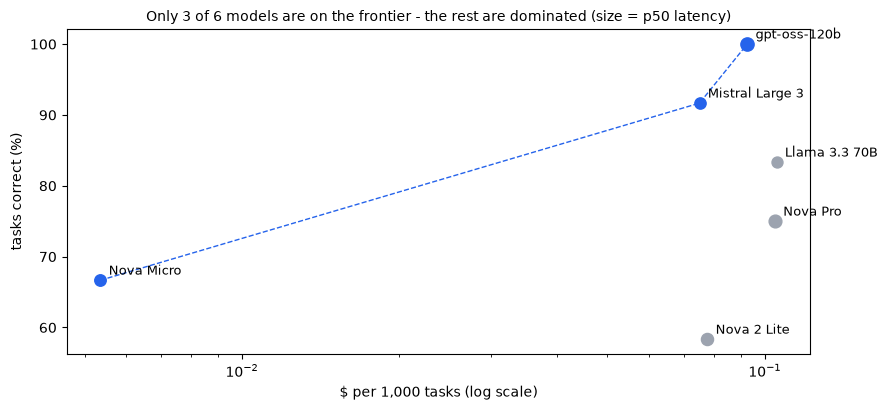

In [8]:
import matplotlib.pyplot as plt

def pareto(points):
    front, best_acc = [], -1
    for s in sorted(points, key=lambda s: (s["$ / 1k tasks"], -s["acc"])):
        if s["acc"] > best_acc:
            front.append(s); best_acc = s["acc"]
    return front

FRONT = pareto(SCORE)
fig, ax = plt.subplots(figsize=(9, 4.2))
for s in SCORE:
    on = s in FRONT
    ax.scatter(s["$ / 1k tasks"], s["acc"] * 100, s=40 + s["latency p50 ms"] / 15, color="#2563eb" if on else "#9ca3af")
    ax.annotate(s["model"], (s["$ / 1k tasks"], s["acc"] * 100), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.plot([s["$ / 1k tasks"] for s in FRONT], [s["acc"] * 100 for s in FRONT], color="#2563eb", lw=1, ls="--")
ax.set_xscale("log"); ax.set_xlabel("$ per 1,000 tasks (log scale)"); ax.set_ylabel("tasks correct (%)")
ax.set_title(f"Only {len(FRONT)} of {len(SCORE)} models are on the frontier - the rest are dominated "
             "(size = p50 latency)", fontsize=10)
plt.tight_layout(); plt.show()

Accuracy per task kind is the input for **routing**: the cheapest model that got every task of a kind right.

In [9]:
ROUTE_CANDIDATES = {}
for kind in dict.fromkeys(t[1] for t in TASKS):
    rows = []
    for s in SCORE:
        rs = [r for r in RESULTS if r["model"] == s["id"] and r["kind"] == kind]
        rows.append((all(r["ok"] for r in rs), sum(r["usd"] for r in rs) / len(rs), s["id"]))
    ok_models = [mid for good, _, mid in sorted(rows, key=lambda x: x[1]) if good]
    ROUTE_CANDIDATES[kind] = ok_models
m.table([[k, ", ".join(m.model_name(x) for x in v) or "– none –"] for k, v in ROUTE_CANDIDATES.items()],
        ["Task kind", "Models with every task right (cheapest first)"])

Task kind,Models with every task right (cheapest first)
classify,"Nova Micro, Mistral Large 3, Nova 2 Lite, Nova Pro, gpt-oss-120b, Llama 3.3 70B"
extract,"Llama 3.3 70B, Mistral Large 3, gpt-oss-120b, Nova 2 Lite"
math,gpt-oss-120b
reason,"Nova Micro, Mistral Large 3, Llama 3.3 70B, Nova Pro, gpt-oss-120b"
grounded,"Nova Micro, gpt-oss-120b, Mistral Large 3, Llama 3.3 70B, Nova Pro"


> **Think about it:** The frontier says which models are never right. What would you need before you drop a model
> that is *on* the frontier but within the confidence interval of a cheaper one?

<details><summary>More questions</summary>

- Which of these numbers changes at 10× the traffic — and which one does not?
- Why is TTFT, not total latency, the number for a chat UI — and the wrong number for a batch job?
</details>

## 2 · A provider-agnostic gateway
The application never names a model. It names a **route** (`classify`, `answer`); the gateway resolves the route
through a routing table that lives in **AWS AppConfig** — validated by a JSON schema, deployed in seconds, no code
release. The same document also carries the retry and breaker settings, and a fault-injection switch for this demo.

In [10]:
ROUTING = {
    "routes": {
        "classify": {"models": [m.NOVA_MICRO, m.GPT_OSS_120B, m.NOVA2_LITE], "max_tokens": 50},
        "answer":   {"models": [m.NOVA_PRO, m.MISTRAL_L3, m.NOVA2_LITE], "max_tokens": 300},
    },
    "retry": {"attempts": 2, "base_seconds": 0.4, "cap_seconds": 4},
    "breaker": {"failures_to_open": 3, "open_seconds": 20},
    "fault_injection": {"model": None, "error": "ServiceUnavailableException", "delay_seconds": 3},
}
SCHEMA = {"type": "object", "required": ["routes", "retry", "breaker"],
          "properties": {"routes": {"type": "object", "additionalProperties": {
              "type": "object", "required": ["models"],
              "properties": {"models": {"type": "array", "minItems": 1, "items": {"type": "string"}},
                             "max_tokens": {"type": "integer", "minimum": 1, "maximum": 4096}}}}}}

def find(items, name):
    return next((i["Id"] for i in items if i["Name"] == name), None)

# §0-style idempotent create: adopt what exists, create what is missing
app_id = find(appconfig.list_applications()["Items"], APP) or appconfig.create_application(Name=APP, Tags=m.TAGS)["Id"]
env_id = find(appconfig.list_environments(ApplicationId=app_id)["Items"], ENV) or \
    appconfig.create_environment(ApplicationId=app_id, Name=ENV, Tags=m.TAGS)["Id"]
prof_id = find(appconfig.list_configuration_profiles(ApplicationId=app_id)["Items"], PROFILE) or \
    appconfig.create_configuration_profile(ApplicationId=app_id, Name=PROFILE, LocationUri="hosted",
                                           Type="AWS.Freeform", Tags=m.TAGS,
                                           Validators=[{"Type": "JSON_SCHEMA", "Content": json.dumps(SCHEMA)}])["Id"]
strat_id = find(appconfig.list_deployment_strategies()["Items"], STRATEGY) or appconfig.create_deployment_strategy(
    Name=STRATEGY, DeploymentDurationInMinutes=0, FinalBakeTimeInMinutes=0, GrowthFactor=100, GrowthType="LINEAR",
    ReplicateTo="NONE", Tags=m.TAGS)["Id"]
print("application", app_id, "· environment", env_id, "· profile", prof_id, "· strategy", strat_id)

application jhklaki · environment a3je8kl · profile tytbngh · strategy 7itcxzk


Publishing = a new **hosted configuration version** (validated against the schema) + a **deployment** to the
environment. A real rollout would use a linear strategy with a bake time and a CloudWatch alarm for automatic rollback.

In [11]:
def publish(config: dict, description: str) -> int:
    # the document carries its own version number, so a client can tell which version it is running
    latest = appconfig.list_hosted_configuration_versions(ApplicationId=app_id, ConfigurationProfileId=prof_id)["Items"]
    doc = {**config, "version": max([v["VersionNumber"] for v in latest] or [0]) + 1}
    version = appconfig.create_hosted_configuration_version(
        ApplicationId=app_id, ConfigurationProfileId=prof_id, Content=json.dumps(doc).encode(),
        ContentType="application/json", Description=description)["VersionNumber"]
    dep = appconfig.start_deployment(ApplicationId=app_id, EnvironmentId=env_id, DeploymentStrategyId=strat_id,
                                     ConfigurationProfileId=prof_id, ConfigurationVersion=str(version),
                                     Description=description)
    m.wait_for(lambda: appconfig.get_deployment(ApplicationId=app_id, EnvironmentId=env_id,
                                                DeploymentNumber=dep["DeploymentNumber"])["State"],
               until=lambda s: s == "COMPLETE" or s, timeout=60, every=1, label=f"deployment of version {version}")
    return version

The client side reads through **AppConfigData**: a session token, polled no faster than the interval the service
returns. The document carries its own `version`, so the client can tell when a deployment has reached it.

In [12]:
class RoutingConfig:
    """The client side: an AppConfigData session, polled at most every `poll` seconds (the service tells us when)."""
    def __init__(self, poll: int = 15):
        self.poll, self.value = poll, None
        self.refresh_now()
    def get(self) -> dict:
        if time.time() >= self.next_poll:
            r = appconfigdata.get_latest_configuration(ConfigurationToken=self.token)
            self.token, self.next_poll = r["NextPollConfigurationToken"], time.time() + r["NextPollIntervalInSeconds"]
            body = r["Configuration"].read()
            if body:                                    # empty body = unchanged since the last poll
                self.value = json.loads(body)
        return self.value

    def wait_for_version(self, version: int, timeout: int = 60) -> float:
        """A COMPLETE deployment reaches the data plane a few seconds later: reload until the client sees it."""
        t0 = time.time()
        while (self.get() or {}).get("version") != version:
            if time.time() - t0 > timeout:
                raise TimeoutError(f"version {version} not visible after {timeout} s")
            time.sleep(2); self.refresh_now()
        return time.time() - t0

    def refresh_now(self):
        """Polling before NextPollIntervalInSeconds is rejected ("Request too early"): a forced reload = a new session."""
        self.token = appconfigdata.start_configuration_session(
            ApplicationIdentifier=app_id, EnvironmentIdentifier=env_id, ConfigurationProfileIdentifier=prof_id,
            RequiredMinimumPollIntervalInSeconds=self.poll)["InitialConfigurationToken"]
        self.next_poll = 0.0

v = publish(ROUTING, "initial routing table")
CONFIG = RoutingConfig()
print(f"client sees version {v} after {CONFIG.wait_for_version(v):.0f} s")
print(json.dumps(CONFIG.get()["routes"], indent=1))

  deployment of version 1 ready after 0 s


client sees version 1 after 0 s
{
 "classify": {
  "models": [
   "us.amazon.nova-micro-v1:0",
   "openai.gpt-oss-120b-1:0",
   "us.amazon.nova-2-lite-v1:0"
  ],
  "max_tokens": 50
 },
 "answer": {
  "models": [
   "us.amazon.nova-pro-v1:0",
   "mistral.mistral-large-3-675b-instruct",
   "us.amazon.nova-2-lite-v1:0"
  ],
  "max_tokens": 300
 }
}


### Error classification, backoff, breaker
Three kinds of failure need three different reactions:
- **retry** the same model (throttling, a 5xx, a timeout) — with exponential backoff and *full jitter* so a fleet of
  clients does not retry in lock-step;
- **fail over** to the next model when retries are exhausted or the model's breaker is open;
- **fail** immediately when the request itself is wrong (`ValidationException`, `AccessDeniedException`): sending a bad
  request to the next provider only fails again — and costs money.

In [13]:
RETRYABLE = {"ThrottlingException", "ServiceUnavailableException", "InternalServerException", "ModelNotReadyException",
             "ModelTimeoutException", "ServiceQuotaExceededException", "ReadTimeout"}
FATAL = {"ValidationException", "AccessDeniedException", "ResourceNotFoundException"}

def classify(err: Exception) -> str:
    code = m.error_code(err) if isinstance(err, ClientError) else "ReadTimeout"
    return "fail" if code in FATAL else "retry" if code in RETRYABLE else "failover"

def backoff(attempt: int, base: float, cap: float) -> float:
    return random.uniform(0, min(cap, base * 2 ** attempt))           # "full jitter"

class CircuitBreaker:
    """CLOSED --n failures--> OPEN --open_seconds--> HALF_OPEN --success--> CLOSED / --failure--> OPEN"""
    def __init__(self):
        self.state, self.failures, self.opened_at = "CLOSED", 0, 0.0
    def allow(self, cfg) -> bool:
        if self.state == "OPEN" and time.time() - self.opened_at >= cfg["open_seconds"]:
            self.state = "HALF_OPEN"                                 # let exactly one probe through
        return self.state != "OPEN"
    def record(self, ok: bool, cfg):
        if ok:
            self.state, self.failures = "CLOSED", 0
        else:
            self.failures += 1
            if self.state == "HALF_OPEN" or self.failures >= cfg["failures_to_open"]:
                self.state, self.opened_at = "OPEN", time.time()

In [14]:
raw = m.bare_client("bedrock-runtime", read_timeout=20)     # no SDK retries: the gateway owns the retry policy

def call_model(model_id: str, messages: list, max_tokens: int, fault: dict) -> dict:
    """One raw Converse call - plus the demo-only fault injection, driven by the AppConfig document."""
    if fault.get("model") == model_id:
        time.sleep(fault["delay_seconds"])
        raise ClientError({"Error": {"Code": fault["error"], "Message": "injected"}}, "Converse")
    return raw.converse(modelId=model_id, messages=messages,
                        inferenceConfig={"maxTokens": max_tokens, "temperature": 0})

The gateway: walk the route's fallback chain; per model ask the breaker, retry what is transient, fail over or fail.

In [15]:
class Gateway:
    def __init__(self, config: RoutingConfig):
        self.config, self.breakers, self.log = config, {}, []

    def invoke(self, route: str, prompt: str, max_tokens: int | None = None) -> dict:
        cfg, t0, trail = self.config.get(), time.perf_counter(), []
        r_cfg, messages = cfg["routes"][route], [{"role": "user", "content": [{"text": prompt}]}]
        for model_id in r_cfg["models"]:
            br = self.breakers.setdefault(model_id, CircuitBreaker())
            if not br.allow(cfg["breaker"]):
                trail.append(f"{m.model_name(model_id)}: breaker OPEN, skipped"); continue
            for attempt in range(cfg["retry"]["attempts"]):
                try:
                    resp = call_model(model_id, messages, max_tokens or r_cfg.get("max_tokens", 300),
                                      cfg["fault_injection"])
                    br.record(True, cfg["breaker"])
                    trail.append(f"{m.model_name(model_id)}: OK")
                    return self._done(route, model_id, t0, trail, m.text_of(resp))
                except (ClientError, ReadTimeoutError, ConnectTimeoutError) as e:
                    action = classify(e)
                    code = m.error_code(e) if isinstance(e, ClientError) else "timeout"
                    trail.append(f"{m.model_name(model_id)}: {code} → {action}")
                    if action == "fail":
                        return self._done(route, None, t0, trail, None, error=str(e)[:120])
                    if action == "failover" or attempt == cfg["retry"]["attempts"] - 1:
                        br.record(False, cfg["breaker"]); break
                    time.sleep(backoff(attempt, cfg["retry"]["base_seconds"], cfg["retry"]["cap_seconds"]))
        return self._done(route, None, t0, trail, None, error="all models failed or open")

    def _done(self, route, model_id, t0, trail, text, error=None):
        open_ = [f"{m.model_name(k)}={b.state}" for k, b in self.breakers.items() if b.state != "CLOSED"]
        row = {"route": route, "served by": m.model_name(model_id) if model_id else "–",
               "ms": (time.perf_counter() - t0) * 1000, "breakers": " ".join(open_) or "all CLOSED",
               "trail": " | ".join(trail), "answer": (text or error or "").replace("**", "")[:60]}
        self.log.append(row)
        return row

One request per route with every provider healthy: the trail column shows which model served it and why.

In [16]:
gw = Gateway(CONFIG)
QUESTION = f"{POLICY}\n\nIn one sentence: is a burst pipe covered?"
m.table([gw.invoke("classify", TASKS[1][2]), gw.invoke("answer", QUESTION)], fmt={"ms": "{:.0f}"})

route,served by,ms,breakers,trail,answer
classify,Nova Micro,587,all CLOSED,Nova Micro: OK,CLAIM
answer,Nova Pro,1008,all CLOSED,Nova Pro: OK,"Yes, water damage from a burst pipe is covered under the Any"


### A provider has a bad day
Publish a new configuration version that makes every call to **Nova Pro** wait 3 s and fail with
`ServiceUnavailableException` (in production the outage is real — or injected with AWS Fault Injection Service).
Then send six requests to the `answer` route, one after the other.

In [17]:
faulty = json.loads(json.dumps(ROUTING)); faulty["fault_injection"]["model"] = m.NOVA_PRO
v = publish(faulty, "fault injection: Nova Pro down")
print(f"client sees version {v} after {CONFIG.wait_for_version(v):.0f} s")
burst = [gw.invoke("answer", QUESTION) for _ in range(6)]
m.table(burst, fmt={"ms": "{:.0f}"})
opened = "OPEN" in burst[-1]["breakers"] and burst[-1]["ms"] < burst[0]["ms"] / 2
print(f"✓ breaker opened after {ROUTING['breaker']['failures_to_open']} failed requests - "
      "later requests fail over at once"
      if opened else "✗ breaker did not open - check the trail column")

  deployment of version 2 ready after 0 s


client sees version 2 after 4 s


route,served by,ms,breakers,trail,answer
answer,Mistral Large 3,6652,all CLOSED,Nova Pro: ServiceUnavailableException → retry | Nova Pro: ServiceUnavailableException → retry | Mistral Large 3: OK,"Yes, a burst pipe is covered under this policy."
answer,Mistral Large 3,6497,all CLOSED,Nova Pro: ServiceUnavailableException → retry | Nova Pro: ServiceUnavailableException → retry | Mistral Large 3: OK,"Yes, a burst pipe is covered under this policy."
answer,Mistral Large 3,6374,Nova Pro=OPEN,Nova Pro: ServiceUnavailableException → retry | Nova Pro: ServiceUnavailableException → retry | Mistral Large 3: OK,"Yes, a burst pipe is covered under this policy."
answer,Mistral Large 3,530,Nova Pro=OPEN,"Nova Pro: breaker OPEN, skipped | Mistral Large 3: OK","Yes, a burst pipe is covered under the AnyCompany Insurance"
answer,Mistral Large 3,381,Nova Pro=OPEN,"Nova Pro: breaker OPEN, skipped | Mistral Large 3: OK","Yes, a burst pipe is covered under this policy."
answer,Mistral Large 3,339,Nova Pro=OPEN,"Nova Pro: breaker OPEN, skipped | Mistral Large 3: OK","Yes, a burst pipe is covered under this policy."


✓ breaker opened after 3 failed requests - later requests fail over at once


> **Think about it:** Compare the `ms` column of the first and the last requests. Where did the time go — and what
> would the user have seen with retries but **no** breaker?

<details><summary>More questions</summary>

- Why retry twice before failing over, and not five times?
- What is the right fallback for a claims *decision* — a weaker model, or a queue and a human?
</details>

Wait for the breaker's open period: the next request is a **half-open probe**. The fault is still there, so it opens
again. Then the provider recovers — the next probe closes the breaker.

In [18]:
time.sleep(ROUTING["breaker"]["open_seconds"] + 1)
probe_fail = gw.invoke("answer", QUESTION)
v = publish(ROUTING, "fault injection off"); CONFIG.wait_for_version(v)
time.sleep(ROUTING["breaker"]["open_seconds"] + 1)
probe_ok = gw.invoke("answer", QUESTION)
m.table([probe_fail, probe_ok], fmt={"ms": "{:.0f}"})
state = gw.breakers[m.NOVA_PRO].state
print("✓ breaker closed again" if state == "CLOSED" else "✗ breaker still " + state)

  deployment of version 3 ready after 0 s


route,served by,ms,breakers,trail,answer
answer,Mistral Large 3,6847,Nova Pro=OPEN,Nova Pro: ServiceUnavailableException → retry | Nova Pro: ServiceUnavailableException → retry | Mistral Large 3: OK,"Yes, a burst pipe is covered under the AnyCompany Insurance"
answer,Nova Pro,962,all CLOSED,Nova Pro: OK,"Yes, a burst pipe is covered under the AnyCompany Insurance"


✓ breaker closed again


### Not every error is an outage
A request the model rejects is **our** bug. The gateway must not fail over — the next provider would reject it too.

In [19]:
bad = gw.invoke("answer", QUESTION, max_tokens=999_999)
m.table([bad], fmt={"ms": "{:.0f}"})
fast_fail = bad["trail"].count("→") == 1 and "fail" in bad["trail"]
print("✓ failed fast, no failover" if fast_fail else "✗ " + bad["trail"])

route,served by,ms,breakers,trail,answer
answer,–,150,all CLOSED,Nova Pro: ValidationException → fail,An error occurred (ValidationException) when calling the Con


✓ failed fast, no failover


## 3 · What it costs per month
Use the measured $/task of §1 and a traffic mix to compare "the best model for everything" with the routed workload.
Assumption (change it): 2 million requests a month, 70 % classification/extraction, 30 % policy questions.

In [20]:
MONTHLY, MIX = 2_000_000, {"classify": 0.40, "extract": 0.30, "math": 0.15, "reason": 0.10, "grounded": 0.05}
usd_per_task = {(r["model"], r["kind"]): [] for r in RESULTS}
for r in RESULTS:
    usd_per_task[(r["model"], r["kind"])].append(r["usd"])
mean = lambda xs: sum(xs) / len(xs)

def monthly(model_for_kind: dict) -> float:
    return sum(MONTHLY * share * mean(usd_per_task[(model_for_kind[k], k)]) for k, share in MIX.items())

single = monthly({k: best["id"] for k in MIX})
routed_models = {k: (ROUTE_CANDIDATES[k] or [best["id"]])[0] for k in MIX}
routed = monthly(routed_models)
m.table([[k, f"{share:.0%}", m.model_name(best["id"]), m.model_name(routed_models[k])] for k, share in MIX.items()],
        ["Kind", "Share", "Single model", "Routed (cheapest with every task right)"])
print(f"single model: ${single:,.0f}/month   routed: ${routed:,.0f}/month   saving {1 - routed / single:.0%}")

Kind,Share,Single model,Routed (cheapest with every task right)
classify,40%,gpt-oss-120b,Nova Micro
extract,30%,gpt-oss-120b,Llama 3.3 70B
math,15%,gpt-oss-120b,gpt-oss-120b
reason,10%,gpt-oss-120b,Nova Micro
grounded,5%,gpt-oss-120b,Nova Micro


single model: $177/month   routed: $101/month   saving 43%


> **Think about it:** The routed bill depends on 12 tasks. Which number on this page would you re-measure first
> before showing it to a CFO?

## Cleanup — don't skip this
Deletes the AppConfig application (deployments must be finished; hosted versions, profile and environment first).
Run it after Part 2 (console) if you showed the configuration there.

In [21]:
def delete_appconfig():
    a = find(appconfig.list_applications()["Items"], APP)
    if a:
        for p in appconfig.list_configuration_profiles(ApplicationId=a)["Items"]:
            for v in appconfig.list_hosted_configuration_versions(ApplicationId=a, ConfigurationProfileId=p["Id"])["Items"]:
                appconfig.delete_hosted_configuration_version(ApplicationId=a, ConfigurationProfileId=p["Id"],
                                                              VersionNumber=v["VersionNumber"])
            appconfig.delete_configuration_profile(ApplicationId=a, ConfigurationProfileId=p["Id"])
        for e in appconfig.list_environments(ApplicationId=a)["Items"]:
            appconfig.delete_environment(ApplicationId=a, EnvironmentId=e["Id"])
        appconfig.delete_application(ApplicationId=a)
    s = find(appconfig.list_deployment_strategies()["Items"], STRATEGY)
    if s:
        appconfig.delete_deployment_strategy(DeploymentStrategyId=s)
    left = [x["Name"] for x in appconfig.list_applications()["Items"] if x["Name"] == APP] + \
           [x["Name"] for x in appconfig.list_deployment_strategies()["Items"] if x["Name"] == STRATEGY]
    print("✓ nothing left" if not left else f"✗ still there: {left}")

delete_appconfig()

✓ nothing left
